# 1.  Installation des dépendances

In [1]:
!pip install retina-face --quiet
!pip install opencv-python-headless --quiet
print("Installation terminée ✅")

Installation terminée ✅


# 2. Imports et configuration

In [2]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import torch
import warnings
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {device}")

DATASET_PATH = "/kaggle/input/datasets/imaneougni/dataset-faces-detection"
os.makedirs("/kaggle/working/results_retinaface", exist_ok=True)
print(f"Dataset path : {DATASET_PATH}")

Device : cpu
Dataset path : /kaggle/input/datasets/imaneougni/dataset-faces-detection


# 3. Chargement des images de test

In [3]:
import glob

extensions = ["*.jpg", "*.jpeg", "*.png",
              "*.JPG", "*.JPEG", "*.PNG"]
all_images = []
for ext in extensions:
    all_images.extend(glob.glob(
        os.path.join(DATASET_PATH, "**", ext), recursive=True))
    all_images.extend(glob.glob(
        os.path.join(DATASET_PATH, ext)))

test_paths = sorted(list(set(all_images)))
print(f"Images trouvées : {len(test_paths)}")
for i, p in enumerate(test_paths):
    img = cv2.imread(p)
    h, w = img.shape[:2] if img is not None else (0, 0)
    print(f"  [{i:02d}] {os.path.basename(p):40s} {w}×{h}")

Images trouvées : 15
  [00] Middle_Eastern.JPG                       163×208
  [01] african.JPG                              312×210
  [02] asien.png                                425×232
  [03] caucasien.JPG                            316×213
  [04] cry.JPG                                  247×211
  [05] face_mask.JPG                            374×211
  [06] kids.png                                 226×218
  [07] multifaces.JPG                           279×179
  [08] normale.JPG                              170×188
  [09] old.png                                  417×238
  [10] partially_covered.JPG                    159×208
  [11] sunglasses.JPG                           119×217
  [12] sunlight.JPG                             312×210
  [13] voile.jpg                                230×295
  [14] women.png                                287×234


# 4. Initialisation RetinaFace

In [4]:
from retinaface import RetinaFace

print("RetinaFace initialisé ✅")
print("Architecture  : ResNet50 + Feature Pyramid Network (FPN)")
print("Landmarks     : 5 points (œil droit, œil gauche, nez,")
print("                          coin bouche droit, coin bouche gauche)")
print("Entrée        : image BGR numpy array")
print("Sortie        : dict {face_1: {facial_area, landmarks, score}}")

2026-05-28 23:54:14.479027: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780012454.503620     140 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780012454.510936     140 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780012454.530149     140 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780012454.530186     140 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780012454.530189     140 computation_placer.cc:177] computation placer alr

RetinaFace initialisé ✅
Architecture  : ResNet50 + Feature Pyramid Network (FPN)
Landmarks     : 5 points (œil droit, œil gauche, nez,
                          coin bouche droit, coin bouche gauche)
Entrée        : image BGR numpy array
Sortie        : dict {face_1: {facial_area, landmarks, score}}


# 5. Fonctions de detection RetinaFace

In [5]:
def detect_retinaface(image_path, threshold=0.90):
    """
    Détecte les visages avec RetinaFace.

    Paramètres
    ----------
    image_path : chemin vers l'image
    threshold  : seuil de confiance minimum (défaut 0.90)

    Retourne
    --------
    boxes     : liste de [x1, y1, x2, y2]
    landmarks : liste de 5 points [[x,y], ...] par visage
    scores    : liste de scores de confiance
    time_ms   : temps d'inférence en millisecondes
    n_faces   : nombre de visages détectés
    """
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        print(f"  ⚠️  Impossible de lire : {image_path}")
        return [], [], [], 0.0, 0

    h, w = img_bgr.shape[:2]

    t0    = time.perf_counter()
    faces = RetinaFace.detect_faces(img_bgr, threshold=threshold)
    t1    = time.perf_counter()

    elapsed_ms = (t1 - t0) * 1000

    # Pas de visage détecté
    if not isinstance(faces, dict) or len(faces) == 0:
        return [], [], [], elapsed_ms, 0

    boxes     = []
    landmarks = []
    scores    = []

    for key, face in faces.items():
        # Boîte englobante [x1, y1, x2, y2]
        fa = face["facial_area"]
        x1 = max(0, int(fa[0]))
        y1 = max(0, int(fa[1]))
        x2 = min(w, int(fa[2]))
        y2 = min(h, int(fa[3]))
        boxes.append([x1, y1, x2, y2])

        # 5 landmarks faciaux
        lm = face["landmarks"]
        landmarks.append([
            [int(lm["right_eye"][0]),    int(lm["right_eye"][1])],
            [int(lm["left_eye"][0]),     int(lm["left_eye"][1])],
            [int(lm["nose"][0]),         int(lm["nose"][1])],
            [int(lm["mouth_right"][0]),  int(lm["mouth_right"][1])],
            [int(lm["mouth_left"][0]),   int(lm["mouth_left"][1])],
        ])

        # Score de confiance
        scores.append(float(face.get("score", 1.0)))

    return boxes, landmarks, scores, elapsed_ms, len(boxes)


# Test rapide
boxes, lmks, scores, ms, n = detect_retinaface(test_paths[0])
print(f"Test rapide sur {os.path.basename(test_paths[0])} :")
print(f"  Visages détectés : {n}")
print(f"  Temps            : {ms:.1f} ms")
if boxes:
    print(f"  Première bbox    : {boxes[0]}")
    print(f"  Score            : {scores[0]:.3f}")
    print(f"  Landmarks[0]     : {lmks[0]}")

2026-05-28 23:54:21.579747: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


26-05-28 23:54:24 - Directory /root/.deepface created
26-05-28 23:54:24 - Directory /root/.deepface/weights created
26-05-28 23:54:24 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100%|██████████| 119M/119M [00:00<00:00, 252MB/s]  


Test rapide sur Middle_Eastern.JPG :
  Visages détectés : 1
  Temps            : 9378.9 ms
  Première bbox    : [29, 51, 123, 176]
  Score            : 0.999
  Landmarks[0]     : [[57, 102], [102, 102], [81, 131], [58, 146], [98, 146]]


# 6. Detection sur toutes les images

In [6]:
print("=" * 60)
print("  RETINAFACE — DÉTECTION SUR TOUTES LES IMAGES")
print("=" * 60)

results_retinaface = []

for path in test_paths:
    boxes, lmks, scores, ms, n = detect_retinaface(path)

    results_retinaface.append({
        "image"    : os.path.basename(path),
        "filepath" : path,
        "n_faces"  : n,
        "time_ms"  : round(ms, 2),
        "boxes"    : boxes,
        "landmarks": lmks,
        "scores"   : scores,
        "detected" : n > 0,
    })

    status = "✅" if n > 0 else "❌"
    score_str = f"  conf={scores[0]:.2f}" if scores else ""
    print(f"  {status}  {os.path.basename(path):40s} "
          f"→ {n} visage(s)  |  {ms:.1f} ms{score_str}")

times  = [r["time_ms"] for r in results_retinaface]
n_ok   = sum(1 for r in results_retinaface if r["detected"])
n_miss = sum(1 for r in results_retinaface if not r["detected"])

print(f"\n{'='*60}")
print(f"  RÉSUMÉ RETINAFACE")
print(f"{'='*60}")
print(f"  Images testées       : {len(test_paths)}")
print(f"  Détections réussies  : {n_ok}")
print(f"  Images manquées      : {n_miss}")
print(f"  Temps moyen          : {np.mean(times):.1f} ms")
print(f"  Temps médian         : {np.median(times):.1f} ms")
print(f"  Temps min / max      : {np.min(times):.1f} / {np.max(times):.1f} ms")
print(f"  FPS estimé           : {round(1000/np.mean(times), 1)}")
print(f"  Landmarks fournis    : Oui (5 points)")

  RETINAFACE — DÉTECTION SUR TOUTES LES IMAGES
  ✅  Middle_Eastern.JPG                       → 1 visage(s)  |  3098.4 ms  conf=1.00
  ✅  african.JPG                              → 1 visage(s)  |  3857.9 ms  conf=0.99
  ✅  asien.png                                → 7 visage(s)  |  4485.0 ms  conf=1.00
  ✅  caucasien.JPG                            → 1 visage(s)  |  3580.4 ms  conf=1.00
  ✅  cry.JPG                                  → 1 visage(s)  |  2770.1 ms  conf=1.00
  ✅  face_mask.JPG                            → 1 visage(s)  |  4319.3 ms  conf=0.98
  ✅  kids.png                                 → 3 visage(s)  |  2494.8 ms  conf=1.00
  ✅  multifaces.JPG                           → 6 visage(s)  |  3778.9 ms  conf=1.00
  ✅  normale.JPG                              → 1 visage(s)  |  2722.1 ms  conf=1.00
  ✅  old.png                                  → 1 visage(s)  |  4342.9 ms  conf=1.00
  ✅  partially_covered.JPG                    → 1 visage(s)  |  3166.5 ms  conf=1.00
  ✅  sunglasses.JP

# 7. Visualisation des detections

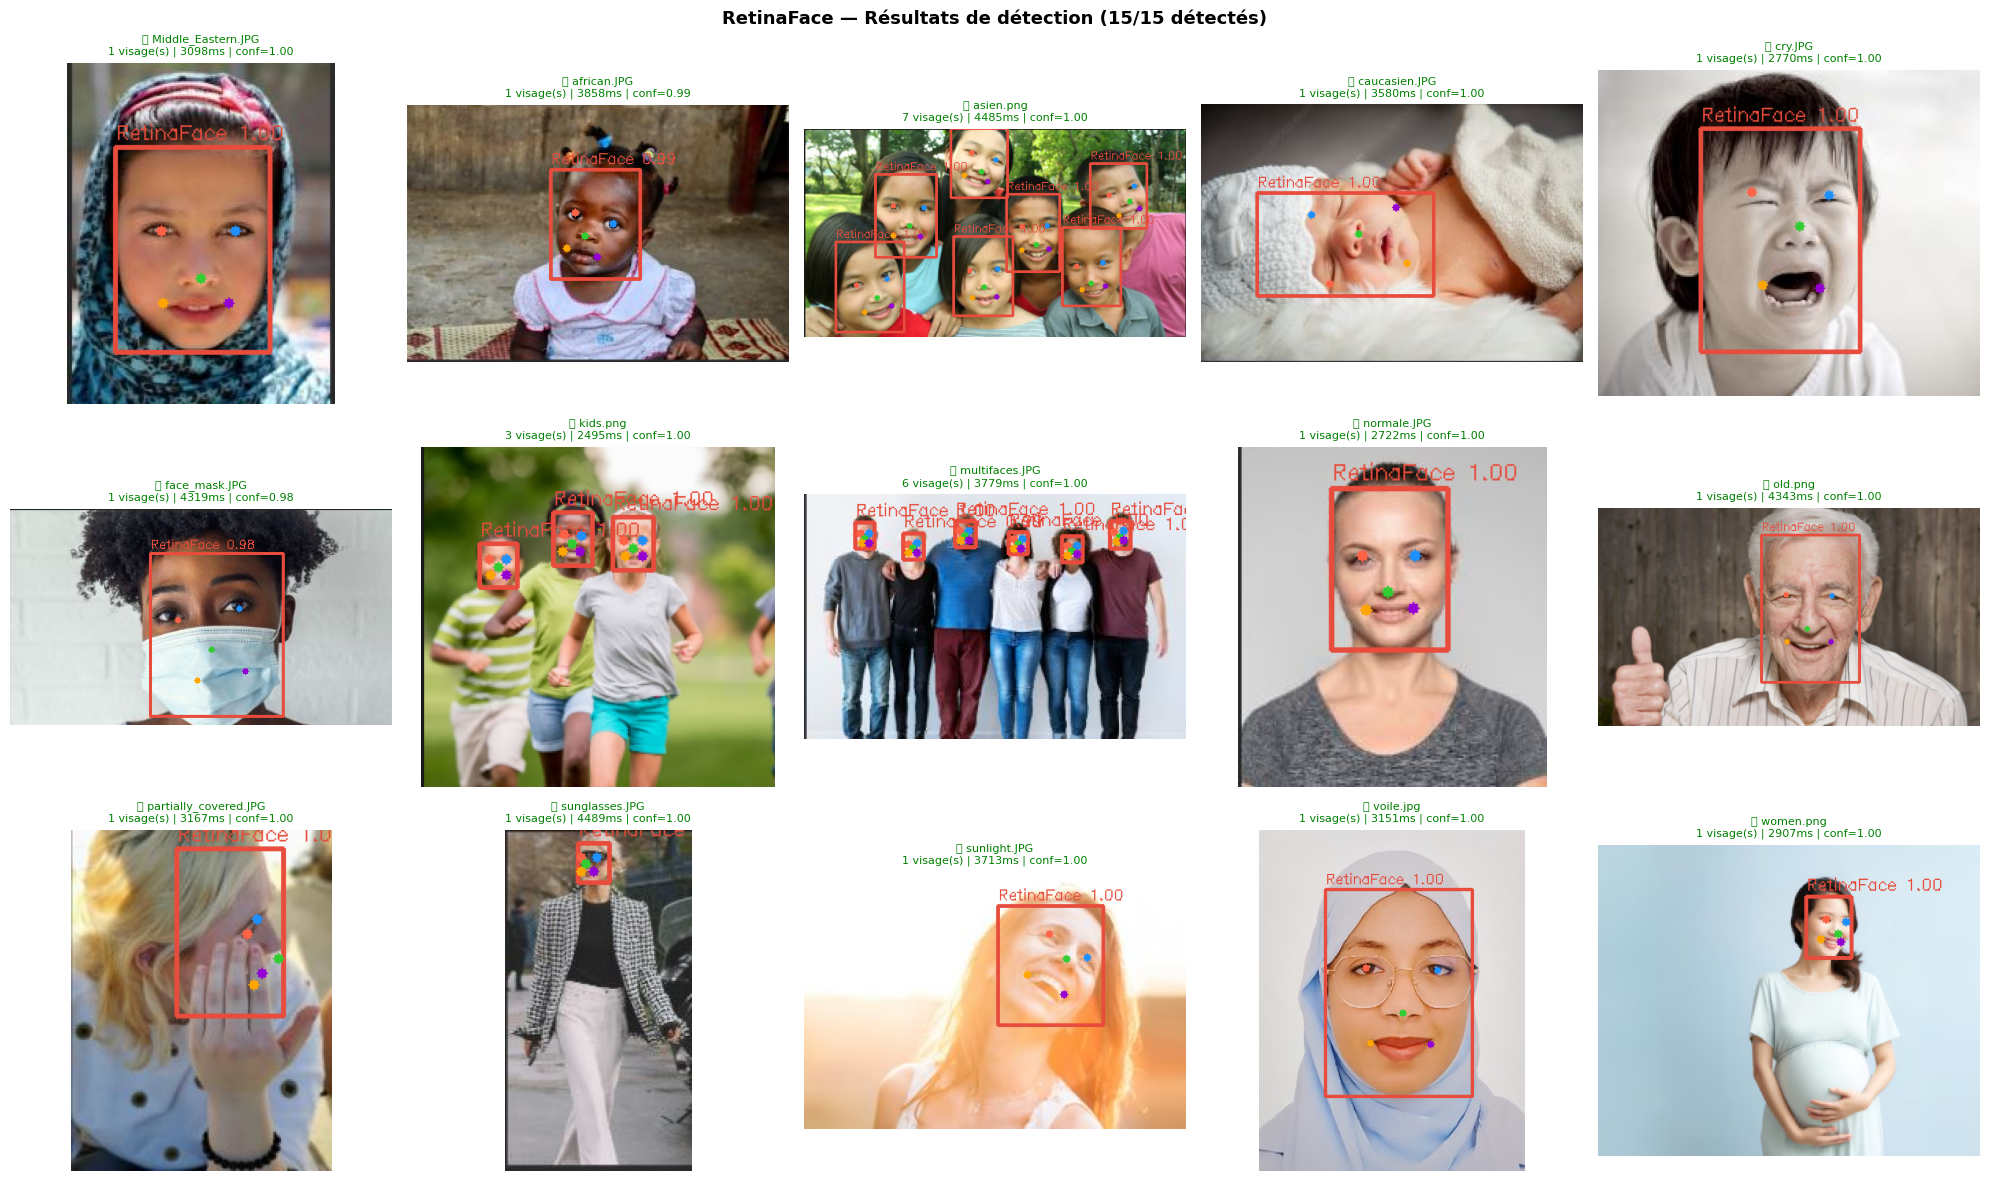

Visualisation sauvegardée ✅


In [7]:
COLOR_BOX = (231, 76,  60)   # rouge RetinaFace
COLOR_LMK = (243, 156, 18)   # orange landmarks
COLOR_TXT = (255, 255, 255)  # blanc texte

def draw_retinaface_result(result):
    img = cv2.imread(result["filepath"])
    if img is None:
        return np.zeros((200, 200, 3), dtype=np.uint8)

    img  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    for i, box in enumerate(result["boxes"]):
        x1, y1, x2, y2 = [int(v) for v in box]

        # Boîte englobante
        cv2.rectangle(img, (x1, y1), (x2, y2), COLOR_BOX, 2)

        # Score de confiance
        label = "RetinaFace"
        if i < len(result["scores"]):
            label += f" {result['scores'][i]:.2f}"
        cv2.putText(img, label, (x1, max(y1 - 5, 0)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, COLOR_BOX, 1)

        # 5 landmarks avec couleurs distinctes par point
        lmk_colors = [
            (255,  99,  71),  # œil droit   — rouge tomate
            ( 30, 144, 255),  # œil gauche  — bleu
            ( 50, 205,  50),  # nez         — vert
            (255, 165,   0),  # bouche droite — orange
            (148,   0, 211),  # bouche gauche — violet
        ]
        if i < len(result["landmarks"]):
            for j, pt in enumerate(result["landmarks"][i]):
                px, py  = int(pt[0]), int(pt[1])
                c       = lmk_colors[j] if j < len(lmk_colors) else COLOR_LMK
                cv2.circle(img, (px, py), 3, c, -1)

    return img


n     = len(results_retinaface)
n_col = min(5, n)
n_row = (n + n_col - 1) // n_col

fig, axes = plt.subplots(n_row, n_col,
                          figsize=(4 * n_col, 4 * n_row))
fig.suptitle(
    f"RetinaFace — Résultats de détection "
    f"({sum(r['detected'] for r in results_retinaface)}/{n} détectés)",
    fontsize=13, fontweight="bold"
)

if n_row == 1 and n_col == 1:
    axes = [[axes]]
elif n_row == 1:
    axes = [list(axes)]
else:
    axes = [list(row) for row in axes]
flat_axes = [ax for row in axes for ax in row]

for i, ax in enumerate(flat_axes):
    if i < len(results_retinaface):
        r       = results_retinaface[i]
        img_viz = draw_retinaface_result(r)
        ax.imshow(img_viz)
        color  = "green" if r["detected"] else "red"
        status = "✅" if r["detected"] else "❌"
        sc_str = (f" | conf={r['scores'][0]:.2f}"
                  if r["scores"] else "")
        ax.set_title(
            f"{status} {r['image']}\n"
            f"{r['n_faces']} visage(s) | {r['time_ms']:.0f}ms{sc_str}",
            fontsize=8, color=color
        )
    ax.axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/results_retinaface/01_detections.png",
            dpi=120, bbox_inches="tight")
plt.show()
print("Visualisation sauvegardée ✅")

# 8. Graphiques des performances

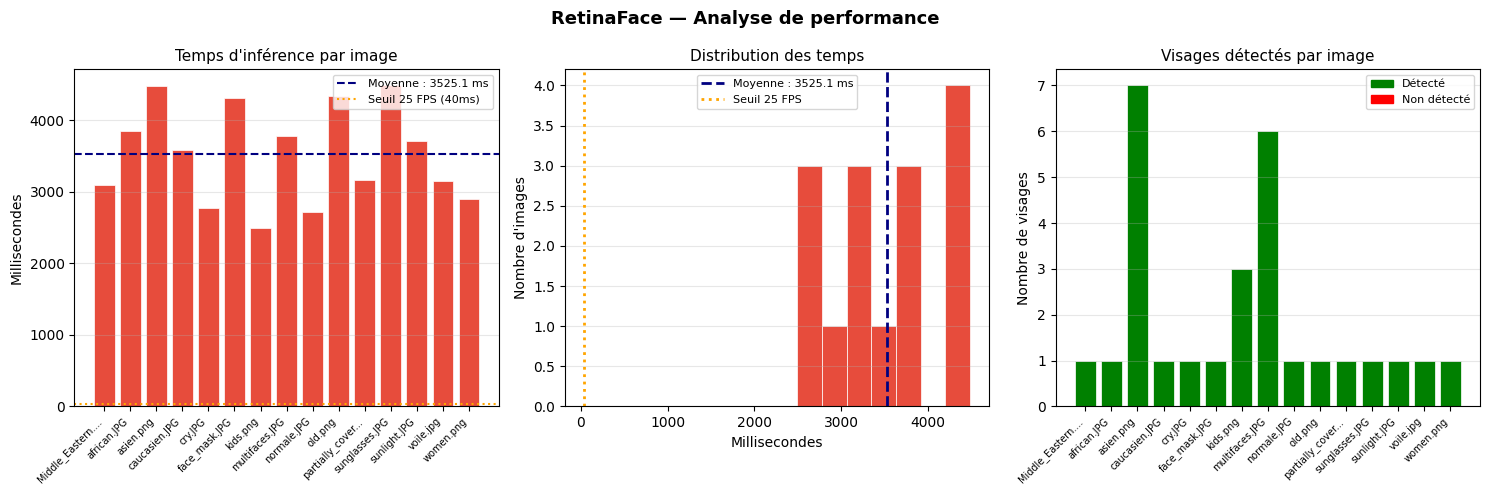

Graphiques sauvegardés ✅


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("RetinaFace — Analyse de performance",
             fontsize=13, fontweight="bold")

COLOR = "#E74C3C"

image_names   = [r["image"][:15] + "..."
                 if len(r["image"]) > 15 else r["image"]
                 for r in results_retinaface]
times_per_img = [r["time_ms"] for r in results_retinaface]

# Temps par image
axes[0].bar(range(len(image_names)), times_per_img,
            color=COLOR, edgecolor="white", linewidth=0.5)
axes[0].axhline(y=np.mean(times_per_img), color="navy",
                linestyle="--", linewidth=1.5,
                label=f"Moyenne : {np.mean(times_per_img):.1f} ms")
axes[0].axhline(y=40, color="orange", linestyle=":",
                linewidth=1.5, label="Seuil 25 FPS (40ms)")
axes[0].set_xticks(range(len(image_names)))
axes[0].set_xticklabels(image_names, rotation=45, ha="right", fontsize=7)
axes[0].set_title("Temps d'inférence par image", fontsize=11)
axes[0].set_ylabel("Millisecondes")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

# Distribution des temps
axes[1].hist(times_per_img,
             bins=max(5, len(times_per_img) // 2),
             color=COLOR, edgecolor="white", linewidth=0.5)
axes[1].axvline(x=np.mean(times_per_img), color="navy",
                linestyle="--", linewidth=2,
                label=f"Moyenne : {np.mean(times_per_img):.1f} ms")
axes[1].axvline(x=40, color="orange", linestyle=":",
                linewidth=2, label="Seuil 25 FPS")
axes[1].set_title("Distribution des temps", fontsize=11)
axes[1].set_xlabel("Millisecondes")
axes[1].set_ylabel("Nombre d'images")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.3)

# Visages détectés + scores de confiance
n_faces_per_img = [r["n_faces"] for r in results_retinaface]
colors_bar = ["green" if n > 0 else "red" for n in n_faces_per_img]
axes[2].bar(range(len(image_names)), n_faces_per_img,
            color=colors_bar, edgecolor="white", linewidth=0.5)
axes[2].set_xticks(range(len(image_names)))
axes[2].set_xticklabels(image_names, rotation=45, ha="right", fontsize=7)
axes[2].set_title("Visages détectés par image", fontsize=11)
axes[2].set_ylabel("Nombre de visages")
axes[2].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[2].legend(handles=[
    Patch(color="green", label="Détecté"),
    Patch(color="red",   label="Non détecté")
], fontsize=8)
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/results_retinaface/02_performance.png",
            dpi=120, bbox_inches="tight")
plt.show()
print("Graphiques sauvegardés ✅")

# 9. Sauvegarde des resultats

In [9]:
df_retinaface = pd.DataFrame([{
    "image"      : r["image"],
    "n_faces"    : r["n_faces"],
    "time_ms"    : r["time_ms"],
    "detected"   : r["detected"],
    "fps_eq"     : round(1000 / r["time_ms"], 1) if r["time_ms"] > 0 else 0,
    "mean_score" : round(np.mean(r["scores"]), 3) if r["scores"] else 0,
} for r in results_retinaface])

df_retinaface.to_csv(
    "/kaggle/working/results_retinaface/retinaface_results.csv",
    index=False)

times = [r["time_ms"] for r in results_retinaface]

summary_retinaface = {
    "detecteur"      : "RetinaFace",
    "n_images"       : len(results_retinaface),
    "n_detected"     : sum(r["detected"] for r in results_retinaface),
    "n_missed"       : sum(not r["detected"] for r in results_retinaface),
    "taux_detection" : round(
        sum(r["detected"] for r in results_retinaface)
        / len(results_retinaface) * 100, 1),
    "time_mean_ms"   : round(np.mean(times), 1),
    "time_median_ms" : round(np.median(times), 1),
    "time_min_ms"    : round(np.min(times), 1),
    "time_max_ms"    : round(np.max(times), 1),
    "fps_estime"     : round(1000 / np.mean(times), 1),
    "landmarks"      : True,
    "n_landmarks"    : 5,
}

print("=" * 60)
print("  RÉSUMÉ FINAL RETINAFACE")
print("=" * 60)
for k, v in summary_retinaface.items():
    print(f"  {k:<25} : {v}")

print(f"\nFichiers sauvegardés dans /kaggle/working/results_retinaface/")
for f in sorted(os.listdir("/kaggle/working/results_retinaface/")):
    print(f"  {f}")

  RÉSUMÉ FINAL RETINAFACE
  detecteur                 : RetinaFace
  n_images                  : 15
  n_detected                : 15
  n_missed                  : 0
  taux_detection            : 100.0
  time_mean_ms              : 3525.1
  time_median_ms            : 3580.4
  time_min_ms               : 2494.8
  time_max_ms               : 4489.1
  fps_estime                : 0.3
  landmarks                 : True
  n_landmarks               : 5

Fichiers sauvegardés dans /kaggle/working/results_retinaface/
  01_detections.png
  02_performance.png
  retinaface_results.csv
